# Week 2 — Tokenization, Sentence Segmentation, N-grams & Zipf's Law
**Project:** French Environmental Text Intelligence (Group 3, French)

**What this notebook does, in plain words.** Before a computer can analyse text, it must cut it into pieces (*tokens*): words, numbers, punctuation. This sounds easy, but it is not: *l'énergie* — one word or two? *9,8 %* — one token or three? *Hauts-de-France*? This notebook compares three tokenizers (simple `split()`, NLTK and spaCy) and a tokenizer written by us, first on the English examples of Tutorial 2 (Part 1), then on **our French environmental corpus** (Part 2). Then it covers the rest of the Week 2 lecture: **n-grams** (sequences of words) with a small language model, and **Zipf's law** (a few words make up most of the text).

| Part | Content | Source |
|---|---|---|
| 1 | Tokens & types, where does a word end, sentence segmentation, subwords | Tutorial 2, Part 1 |
| 2 | Tasks A–H on our French corpus | Tutorial 2, Part 2 |
| 3 | Our own regex tokenizer for French, evaluated against a hand-made gold standard | Lecture homework |
| 4 | N-grams and a bigram language model | Lecture, N-grams |
| 5 | Word frequencies and Zipf's law | Lecture, Linguistic analysis |


## Setup

In [1]:
# !pip install nltk spacy
# !python -m spacy download fr_core_news_md
import re, json, statistics, urllib.parse, urllib.request
from collections import Counter
from pathlib import Path

import nltk
for pkg in ['punkt', 'punkt_tab']:
    nltk.download(pkg, quiet=True)
import spacy
from nltk.tokenize import word_tokenize, sent_tokenize
from nlp_utils import load_corpus

def make_tokenizers(lang='en', language='english'):
    nlp_ = spacy.blank(lang)       # a blank spaCy pipeline: only its tokenizer
    return {
        'split': lambda t: t.split(),                                  # whitespace
        'nltk': lambda t: word_tokenize(t, language=language),
        'spaCy': lambda t: [x.text for x in nlp_.tokenizer(t) if not x.is_space],
    }

tokenizers = make_tokenizers()       # English, for the examples of Part 1
print('spaCy', spacy.__version__, '| NLTK', nltk.__version__)

[nltk_data] Error loading punkt: Security Violation [pathsec.urlopen]:
[nltk_data]     refusing a proxied fetch of
[nltk_data]     'https://raw.githubusercontent.com/nltk/nltk_data/gh-
[nltk_data]     pages/index.xml'. A configured proxy performs the
[nltk_data]     egress, so NLTK cannot pin the validated IP and SSRF
[nltk_data]     protection cannot be enforced (CWE-918). If and only
[nltk_data]     if the proxy is trusted to be SSRF-safe, opt in via
[nltk_data]     NLTK_ALLOW_PROXIED_URLOPEN=1 or
[nltk_data]     nltk.pathsec.ALLOW_PROXIED_FETCH=True.
[nltk_data] Error loading punkt_tab: Security Violation
[nltk_data]     [pathsec.urlopen]: refusing a proxied fetch of
[nltk_data]     'https://raw.githubusercontent.com/nltk/nltk_data/gh-
[nltk_data]     pages/index.xml'. A configured proxy performs the
[nltk_data]     egress, so NLTK cannot pin the validated IP and SSRF
[nltk_data]     protection cannot be enforced (CWE-918). If and only
[nltk_data]     if the proxy is trusted to be S

spaCy 3.8.18 | NLTK 3.10.4


---
# Part 1 — In class (English examples of Tutorial 2)
Step 1 of each exercise is done **on paper**. Below are our paper answers next to the code output, so you can compare.

## 2. Tokens and types
- **Token:** one occurrence of a word (or punctuation mark) in a text.
- **Type:** one distinct word form. *"to be or not to be"* has 6 tokens but only 4 types (*to, be, or, not*).
- **Vocabulary (V):** the set of all types of a text or corpus.

In [2]:
text = "Tea is good, but coffee is better, and water is best of all."
for name, f in tokenizers.items():
    toks = f(text)
    print(f'{name:6s} {len(toks):2d} tokens {len(set(toks)):2d} types  TTR={len(set(toks))/len(toks):.2f}')
    print('      ', toks)

split  13 tokens 11 types  TTR=0.85
       ['Tea', 'is', 'good,', 'but', 'coffee', 'is', 'better,', 'and', 'water', 'is', 'best', 'of', 'all.']
nltk   16 tokens 13 types  TTR=0.81
       ['Tea', 'is', 'good', ',', 'but', 'coffee', 'is', 'better', ',', 'and', 'water', 'is', 'best', 'of', 'all', '.']
spaCy  16 tokens 13 types  TTR=0.81
       ['Tea', 'is', 'good', ',', 'but', 'coffee', 'is', 'better', ',', 'and', 'water', 'is', 'best', 'of', 'all', '.']


**Paper answer (Step 1).** We count punctuation marks as tokens, because they carry information (a "!!!" matters for sentiment):
*Tea | is | good | , | but | coffee | is | better | , | and | water | is | best | of | all | .* → **16 tokens**, and *is* (×3) and *,* (×2) repeat, so **13 types**, type/token ratio = 13/16 = **0.81**. Without punctuation: 13 tokens, 11 types (0.85).

**Discussion (Step 3).** NLTK and spaCy agree with our paper answer (16 / 13). `split()` finds only 13 tokens. Its type count (11) looks right only by accident: it glues punctuation to words (*good,*, *all.*), so *good,* and *good* would count as two different types in a longer text. We prefer NLTK/spaCy here.

## 3. Where does a word end?

In [3]:
sentences = {
 1: "I can't believe y'all didn't know we'd already left.",
 2: "The state-of-the-art e-mail client is a well-known, user-friendly tool.",
 3: "Revenue rose from 1,234.56 to 1,450.20 dollars (+17.5%).",
 4: "Dial +44 20 7946 0958 at 09:15 or write by 2025-01-31.",
 5: "@maria_k loving this weather #SundayVibes :-D www.example.org/help",
 6: "They ate ice cream and a hot dog in Buenos Aires.",
 7: 'He said: "Wait..." and left (quickly)!',
}
for i, s in sentences.items():
    print(f'{i}. {s}')
    for name, f in tokenizers.items():
        toks = f(s)
        print(f'   {name:6s}{len(toks):3d}', toks)

1. I can't believe y'all didn't know we'd already left.
   split   9 ['I', "can't", 'believe', "y'all", "didn't", 'know', "we'd", 'already', 'left.']
   nltk   13 ['I', 'ca', "n't", 'believe', "y'all", 'did', "n't", 'know', 'we', "'d", 'already', 'left', '.']
   spaCy  14 ['I', 'ca', "n't", 'believe', "y'", 'all', 'did', "n't", 'know', 'we', "'d", 'already', 'left', '.']
2. The state-of-the-art e-mail client is a well-known, user-friendly tool.
   split   9 ['The', 'state-of-the-art', 'e-mail', 'client', 'is', 'a', 'well-known,', 'user-friendly', 'tool.']
   nltk   11 ['The', 'state-of-the-art', 'e-mail', 'client', 'is', 'a', 'well-known', ',', 'user-friendly', 'tool', '.']
   spaCy  23 ['The', 'state', '-', 'of', '-', 'the', '-', 'art', 'e', '-', 'mail', 'client', 'is', 'a', 'well', '-', 'known', ',', 'user', '-', 'friendly', 'tool', '.']
3. Revenue rose from 1,234.56 to 1,450.20 dollars (+17.5%).
   split   8 ['Revenue', 'rose', 'from', '1,234.56', 'to', '1,450.20', 'dollars', '(+17.

**Where the tokenizers disagree, and who is right** (the kinds of problem are in bold):

| # | Kind of problem | What happens | Our opinion |
|---|---|---|---|
| 1 | **Contractions / clitics** | NLTK and spaCy split *ca \| n't*, *did \| n't*, *we \| 'd* (Penn Treebank convention). spaCy also splits *y' \| all* | Splitting is useful (*n't* = *not*). *y'all* is better kept as one token, so NLTK is right there |
| 2 | **Hyphenation** | NLTK keeps *state-of-the-art*, *e-mail*, *well-known*. spaCy (English) splits at every hyphen: 23 tokens | NLTK: these are single words |
| 3 | **Numbers, dates, phone numbers** | All keep *1,234.56*. NLTK keeps *2025-01-31*, spaCy cuts it into 5 pieces. All cut the phone number into 4 | Dates and phone numbers should be one unit, but **there is no single right answer**: it depends on the task |
| 4 | **Social media, URLs** | NLTK splits *@ \| maria_k*, *# \| SundayVibes* and breaks the emoticon into *: \| -D*. spaCy keeps *@maria_k* and *:-D* but splits *#*. All keep the URL | spaCy is closer. A hashtag should stay one token |
| 5 | **Multi-word expressions** | *ice cream*, *hot dog*, *Buenos Aires* are split by every tokenizer | Not a tokenizer's job: it needs a separate step (multi-word expressions, NER) |
| 6 | **Quotes and ellipsis** | NLTK rewrites `"` as ` `` ` and `''` (it changes the text!). spaCy keeps `"`. Both keep *...* as one token | spaCy |

**Why do two good libraries disagree?** They follow different **conventions**. NLTK reproduces the Penn Treebank rules (built for English news text). spaCy uses its own rules plus exception lists, and splits hyphens so that its parser can analyse the parts. Neither is "wrong": a token is a *decision* that depends on the task (as the lecture says).

## 4. Tokenizing texts

In [4]:
examples = {
 'A': """Dr. Elena Marković (born 12 March 1968) is a Serbian-born
 astrophysicist who has worked at the Kessler-Institut für Astrophysik since
 1999. She is best known for her co-discovery of the 2.5-kilometre asteroid
 2004 XY7, which was named after her grandmother's village. In 2015 she
 received the Hartwell Prize, worth £15,000, and she has published more than
 120 papers (see Table 2 of her CV).""",
 'B': """The ZX-300 is a 5G-capable smartphone released on 4 September 2023 at
 a price of $649.99. Its 6.1-inch OLED display has a refresh rate of 120 Hz,
 and the battery lasts about 18 h in normal use. According to the
 manufacturer, 92% of the casing is recycled aluminium.[1] More details are
 available at www.zx300-example.org/specs or by e-mail to
 support@zx300-example.org.""",
 'C': """Valmont-sur-Aure is a small town in northern France with about 9,800
 inhabitants. Its old quarter, known locally as "La Vieille Ville", is famous
 for its Saturday market, its narrow streets and the annual Fête de l'Aure,
 held every June. The town was founded around 50 B.C. and nobody remembers
 exactly when the first bridge was built! Today the Dubois & Fils bakery on
 Rue de l'Hôtel-de-Ville is a landmark; locals say it sells "the best bread in
 the region".""",
}
for k in examples:
    examples[k] = examples[k].replace('\n', ' ')

def compare(text, toks=tokenizers):
    outputs = {name: f(text) for name, f in toks.items()}
    shared = set.intersection(*[set(t) for t in outputs.values()])
    for name, t in outputs.items():
        print(f'{name:6s}{len(t):4d} tokens')
        print('    ', [w for w in t if w not in shared])

for k in examples:
    print('=== Text', k); compare(examples[k])

=== Text A
split   64 tokens
     ['(born', '1968)', 'Serbian-born', 'Kessler-Institut', '1999.', 'co-discovery', '2.5-kilometre', 'XY7,', "grandmother's", 'village.', 'Prize,', '£15,000,', '(see', 'CV).']
nltk    75 tokens
     ['(', 'born', '1968', ')', 'Serbian-born', 'Kessler-Institut', '1999', '.', 'co-discovery', '2.5-kilometre', 'XY7', ',', 'grandmother', "'s", 'village', '.', 'Prize', ',', '£15,000', ',', '(', 'see', 'CV', ')', '.']
spaCy   84 tokens
     ['(', 'born', '1968', ')', 'Serbian', '-', 'born', 'Kessler', '-', 'Institut', '1999', '.', 'co', '-', 'discovery', '2.5', '-', 'kilometre', 'XY7', ',', 'grandmother', "'s", 'village', '.', 'Prize', ',', '£', '15,000', ',', '(', 'see', 'CV', ')', '.']
=== Text B
split   59 tokens
     ['5G-capable', '$649.99.', '6.1-inch', 'Hz,', 'use.', 'manufacturer,', '92%', 'aluminium.[1]', 'e-mail', 'support@zx300-example.org.']
nltk    72 tokens
     ['5G-capable', '$', '649.99', '.', '6.1-inch', 'Hz', ',', 'use', '.', 'manufacturer', ',

**Discussion.** Our hand count for the first sentence of text A (*Dr. Elena Marković … since 1999.*) is **24 tokens** (with *Dr.*, *Serbian-born* and *Kessler-Institut* as single tokens, and the brackets and the final period as separate tokens).

| String | split | nltk | spaCy | Right (our opinion) |
|---|---|---|---|---|
| *Serbian-born* (A) | 1 | 1 | 3 (*Serbian - born*) | 1 token: nltk |
| *£15,000,* (A) | 1 (glued comma) | *£15,000* *,* | *£* *15,000* *,* | *£ \| 15,000 \| ,*: spaCy |
| *support@zx300-example.org.* (B) | 1 (glued period) | *support @ zx300-example.org .* | *support@zx300-example.org .* | spaCy |
| *aluminium.[1]* (B) | 1 | *aluminium . [ 1 ]* | *aluminium.[1 ]* | nltk |
| *"La Vieille Ville"* (C) | glued quotes | `` `` `` and `''` (text changed) | `"` kept | spaCy |
| *50 B.C.* (C) | *B.C.* | *B.C .* | *B.C.* | split / spaCy |

**Which tokenizer for these texts?** spaCy, because it keeps e-mail addresses and abbreviations (*B.C.*) intact and does not change the quotes. Its weakness is hyphenated words (*Valmont-sur-Aure* becomes 5 tokens with the English rules).

## 5. Sentence segmentation

In [5]:
text = ("Dr. Okafor lives at 12 St. John's Road. She works for Acme Inc. and "
        "arrives at 8:30. Is she late again? No... she isn't! "
        'He replied: "See you at the meeting." Then he left. '
        "The report (see Fig. 3) costs approx. $4.50 per copy, i.e. cheap.")
sp = spacy.blank('en')
sp.add_pipe('sentencizer')                                # spaCy sentence splitter

def naive(t): return re.split(r'(?<=[.!?])\s+(?=[A-Z])', t)         # ". " + capital letter
def punkt(t): return sent_tokenize(t)                                 # NLTK
def spacy_s(t): return [s.text for s in sp(t).sents]                  # spaCy

for name, f in [('naive', naive), ('punkt', punkt), ('spaCy', spacy_s)]:
    print(name, len(f(text)))
    for s in f(text):
        print('   ', s)
for k, t in examples.items():
    print('Text', k, {name: len(f(t)) for name, f in [('naive', naive), ('punkt', punkt), ('spaCy', spacy_s)]})

naive 8
    Dr.
    Okafor lives at 12 St.
    John's Road.
    She works for Acme Inc. and arrives at 8:30.
    Is she late again?
    No... she isn't!
    He replied: "See you at the meeting." Then he left.
    The report (see Fig. 3) costs approx. $4.50 per copy, i.e. cheap.


punkt 10
    Dr. Okafor lives at 12 St. John's Road.
    She works for Acme Inc. and arrives at 8:30.
    Is she late again?
    No... she isn't!
    He replied: "See you at the meeting."
    Then he left.
    The report (see Fig.
    3) costs approx.
    $4.50 per copy, i.e.
    cheap.
spaCy 9
    Dr. Okafor lives at 12 St. John's Road.
    She works for Acme Inc. and arrives at 8:30.
    Is she late again?
    No... she isn't!
    He replied: "See you at the meeting."
    Then he left.
    The report (see Fig.
    3) costs approx.
    $4.50 per copy, i.e. cheap.
Text A {'naive': 4, 'punkt': 3, 'spaCy': 3}


Text B {'naive': 3, 'punkt': 4, 'spaCy': 3}
Text C {'naive': 4, 'punkt': 5, 'spaCy': 4}


**Paper answer.** The text has **7 sentences**: (1) *Dr. Okafor … Road.* (2) *She works … 8:30.* (3) *Is she late again?* (4) *No... she isn't!* (5) *He replied: "See you at the meeting."* (6) *Then he left.* (7) *The report (see Fig. 3) costs approx. $4.50 per copy, i.e. cheap.*

| Method | Found | Where it cuts wrongly | Why |
|---|---|---|---|
| naive rule (". " + capital) | 8 | after *Dr.* and *St.*, but it **misses** the boundary after *meeting."* | an abbreviation followed by a name looks like a sentence end. A quote between the period and the space hides the boundary |
| Punkt (NLTK) | 10 | after *Fig.*, *approx.* and *i.e.* | Punkt learned *Dr.*, *St.*, *Inc.* as abbreviations, but not these three |
| spaCy sentencizer | 9 | after *Fig.* and *approx.* | simple punctuation rules with a few exceptions |

The naive rule only looks at the next character. Punkt is a **statistical** model trained on a corpus to recognise abbreviations. spaCy's `sentencizer` is **rule-based** (the full spaCy pipeline can also use the parser).

**Two texts of our own that break a method:**
- *"The meeting is at 5 p.m. Tomorrow it moves to 9 a.m."*: no method can tell from punctuation alone whether *p.m.* ends the sentence.
- *"Il est arrivé le 3 janv. Puis il est reparti."*: the French abbreviation *janv.* followed by a capital fools the naive rule.

## 6. Subword tokens
Modern language models cut rare words into frequent pieces (BPE, WordPiece, SentencePiece). This cell needs `pip install transformers sentencepiece` and an internet connection the first time (the tokenizers are downloaded from Hugging Face). **Run it on your laptop**; it is skipped automatically when there is no connection.

In [6]:
words = ["unbreakable", "undoubtedly", "reorganisation", "microwaveable"]
my_sentence = "Les émissions de gaz à effet de serre ont baissé grâce aux énergies renouvelables."
try:
    from transformers import AutoTokenizer
    hf = {'BERT': AutoTokenizer.from_pretrained('bert-base-uncased'),
          'GPT-2': AutoTokenizer.from_pretrained('gpt2'),
          'XLM-R': AutoTokenizer.from_pretrained('xlm-roberta-base')}
    for w in words + [my_sentence, 'Unbreakable']:
        print(w)
        for name, tok in hf.items():
            pieces = tok.tokenize(w)
            print(f'   {name:6s}{len(pieces):3d}', pieces)
except Exception as e:
    print('Skipped (needs transformers + internet):', type(e).__name__, str(e)[:120])

Skipped (needs transformers + internet): ModuleNotFoundError No module named 'transformers'


**What to look for when you run it:**
1. Compare the pieces with your paper split (e.g. *un + break + able*). Models cut by **frequency**, not by meaning, so pieces do not always match morphemes.
2. Special characters: BERT marks pieces that continue a word with **`##`**. GPT-2 marks a piece that starts after a space with **`Ġ`**. XLM-R (SentencePiece) marks the start of a word with **`▁`**.
3. For the French sentence, BERT (English vocabulary) and GPT-2 need many more pieces than XLM-R (multilingual): accented words like *émissions* or *énergies* are split into small fragments. For users of French, this means longer inputs, so a higher cost and less context fits in the model.
4. *Unbreakable* with a capital: `bert-base-uncased` lowercases first, so nothing changes. GPT-2 and XLM-R are case-sensitive, so they give other pieces.

---
# Part 2 — Our French corpus (Tutorial 2, Part 2)

## 7. Our corpus
The Tutorial asks for at least 8 files of about 200 words or more, at least **three different kinds of text**, and **no cleaning**. Our corpus now has 107 texts of **four kinds**, all about the environment, all under open licences:

| Kind | Source | Licence | Files |
|---|---|---|---|
| encyclopedia | French Wikipedia (article introductions) | CC BY-SA 4.0 | 81 |
| news | French Wikinews articles | CC BY 2.5 / CC BY-SA 4.0 | 16 |
| discussion | Wikipedia talk pages (forum-like, with signatures and dates) | CC BY-SA 4.0 | 8 |
| legal | Official texts on Wikisource (Charte de l'environnement, Charte mondiale de la nature) | public domain | 2 |

The news, discussion and legal texts were added this week **without cleaning**, as required: signatures, dates, `(CET)`, `Répondre`, article numbers and so on are kept exactly as found. All texts were collected by `collect_corpus.py`; title, URL, date and licence of every file are in `corpus/metadata.csv`.

In [7]:
LANG = 'fr'                # language code of our corpus
LANG_NLTK = 'french'       # NLTK name, used by word_tokenize and sent_tokenize
USE_PUNKT = True           # NLTK has a Punkt model for French

corpus_tok = make_tokenizers(LANG, LANG_NLTK)
sentencizer = spacy.blank(LANG)
sentencizer.add_pipe('sentencizer')

def split_sentences(text):
    if USE_PUNKT:
        return sent_tokenize(text, language=LANG_NLTK)
    return [s.text.strip() for s in sentencizer(text).sents]

docs = load_corpus()
files = [Path('corpus') / d['file'] for d in docs]
texts = [d['text'] for d in docs]
kind_of = {d['file']: d['kind'] for d in docs}
print(len(texts), 'texts loaded')

107 texts loaded


### Task A — One row per file

In [8]:
import pandas as pd
pd.set_option('display.max_colwidth', 60)
table_a = pd.DataFrame([{
    'file': d['file'], 'source': d['url'], 'kind': d['kind'], 'category': d['category'],
    'chars': len(d['text']), 'whitespace_tokens': len(d['text'].split())} for d in docs])
table_a.to_csv('corpus_overview.csv', index=False)      # the full table, one row per file
print(table_a.groupby('kind')[['chars', 'whitespace_tokens']].agg(['count', 'sum', 'mean']).round(0))
table_a.head(8)

             chars                 whitespace_tokens              
             count     sum    mean             count    sum   mean
kind                                                              
discussion       8   21998  2750.0                 8   3444  430.0
encyclopedia    81  118776  1466.0                81  18139  224.0
legal            2    5697  2848.0                 2    862  431.0
news            16   32398  2025.0                16   5140  321.0


,file,source,kind,category,chars,whitespace_tokens
0,text01.txt,https://fr.wikipedia.org/wiki/Dioxyde_de_carbone,encyclopedia,emissions,1821,297
1,text02.txt,https://fr.wikipedia.org/wiki/M%C3%A9thane,encyclopedia,emissions,1909,297
2,text03.txt,https://fr.wikipedia.org/wiki/Empreinte_carbone,encyclopedia,emissions,1907,278
3,text04.txt,https://fr.wikipedia.org/wiki/Bilan_carbone,encyclopedia,emissions,1823,272
4,text05.txt,https://fr.wikipedia.org/wiki/Effet_de_serre,encyclopedia,emissions,1854,280
5,text06.txt,https://fr.wikipedia.org/wiki/Neutralit%C3%A9_carbone,encyclopedia,emissions,1704,269
6,text07.txt,https://fr.wikipedia.org/wiki/Protoxyde_d%27azote,encyclopedia,emissions,1945,299
7,text08.txt,https://fr.wikipedia.org/wiki/D%C3%A9forestation,encyclopedia,emissions,1045,153


**Description of our corpus (Task A).** The corpus contains **107 French texts about the environment** (about 27,600 whitespace tokens), in four topic categories (emissions, renewable energy, pollution, climate policy) and **four kinds of text**:
- **encyclopedia:** 81 Wikipedia introductions of about 220 words.
- **news:** 16 Wikinews articles of about 320 words.
- **discussion:** 8 Wikipedia talk pages of about 430 words, written in a forum style with signatures and dates.
- **legal:** 2 official texts (the French *Charte de l'environnement* and the UN *Charte mondiale de la nature*).

The new texts were not cleaned, so they keep URLs, e-mail addresses, timestamps and typographic apostrophes exactly as published. The full table (one row per file, with source, kind, characters and whitespace tokens) is saved as `corpus_overview.csv`.

### Task B — Problem hunt

In [9]:
patterns = {
  'url':          r'https?://\S+|www\.\S+',
  'e-mail':       r'[\w.+-]+@[\w-]+(?:\.[\w-]+)+',
  'hashtag/@':    r'[#@]\w+',
  'number':       r'\d[\d.,:/-]*\d|\d',
  'hyphenated':   r'\w+(?:-\w+)+',
  'apostrophe':   r"\w+['\u2019]\w+",
  'abbreviation': r'\b[A-Z][a-z]{0,3}\.',
  'other symbol': r"[^\w\s.,;:!?'\"()\-]",
}
for name, pat in patterns.items():
    found = Counter(m for t in texts for m in re.findall(pat, t))
    print(f'{name:13s} {sum(found.values()):5d} {found.most_common(3)}')

print('\nMatches per 100 whitespace tokens, by kind of text:')
for kind in ['encyclopedia', 'news', 'discussion', 'legal']:
    ts = [d['text'] for d in docs if d['kind'] == kind]
    n_ws = sum(len(t.split()) for t in ts)
    hits = sum(len(re.findall(p, t)) for p in patterns.values() for t in ts)
    print(f'  {kind:13s} {100 * hits / n_ws:5.1f}')

url               6 [('www.outilssolaires.com.', 1), ('http://www.ehponline.org/docs/2007/115-4/toc.html)', 1), ('https://web.archive.org/web/20120521090317/http://www.centreinfo-energie.com/generator2.asp?xml=%2Fsilos%2Fong%2Foilsands%2FoilsandsAndHeavyOilOverview01XML.asp&template=1%2C1%2C1', 1)]
e-mail            1 [('commercial@energysolar.com', 1)]
hashtag/@         3 [('@Lebrouillard', 1), ('@energysolar', 1), ('#Principales', 1)]
number         1018 [('2', 100), ('1', 27), ('2015', 25)]
hyphenated      202 [('États-Unis', 19), ('est-à-dire', 11), ('Royaume-Uni', 5)]
apostrophe     1624 [("l'énergie", 67), ("d'un", 45), ("d'une", 34)]
abbreviation     22 [('Art.', 10), ('M.', 3), ('O.', 2)]
other symbol    813 [('’', 217), ('%', 168), ('«', 134)]

Matches per 100 whitespace tokens, by kind of text:
  encyclopedia   12.5
  news           14.4
  discussion     15.5
  legal          18.2


In [10]:
# French-specific patterns that are not in the Tutorial's list
fr_patterns = {
  'elision (l\', d\', qu\'...)': r"\b(?:[lLdDjJmMnNsStTcC]|[qQ]u|[lL]orsqu|[pP]uisqu|[jJ]usqu)['\u2019]\w+",
  'decimal comma':   r'\d+,\d+',
  'percent':         r'\d[\d,\s\u00a0]*\s?%',
  'non-breaking sp.': r'\u00a0|\u202f',
  'guillemets « »':  r'[«»]',
  'signature date':  r'\d{1,2} \w+ \d{4} à \d{1,2}:\d{2} \(CES?T\)',
}
for name, pat in fr_patterns.items():
    found = Counter(m for t in texts for m in re.findall(pat, t))
    print(f'{name:22s} {sum(found.values()):5d} {[x for x, _ in found.most_common(3)]}')

elision (l', d', qu'...)  1617 ["l'énergie", "d'un", "d'une"]
decimal comma            113 ['2,5', '1,5', '2,2']
percent                  160 ['1%', '20 %', '1 %']
non-breaking sp.         217 ['\xa0', '\u202f']
guillemets « »           267 ['«', '»']
signature date            39 ['11 décembre 2023 à 11:46 (CET)', '11 décembre 2023 à 12:58 (CET)', '11 décembre 2023 à 14:07 (CET)']


**Results (Task B).**

| Category | Matches | Three examples |
|---|---|---|
| apostrophe | 1,624 | *l'énergie, d'un, d'une* |
| number | 1,018 | *2, 1, 2015* |
| other symbol | 813 | *’* (typographic apostrophe), *%*, *«* |
| hyphenated | 202 | *États-Unis, est-à-dire, Royaume-Uni* |
| abbreviation | 22 | *Art., M., O.* |
| url | 6 | an archive.org link of 230 characters |
| hashtag/@ | 3 | *@Lebrouillard, @energysolar* |
| e-mail | 1 | *commercial@energysolar.com* |

- **Most frequent category:** apostrophes. This is typical of French: 1,617 of them are **elisions** (*l'*, *d'*, *qu'*) that a whitespace tokenizer cannot split.
- **French-specific problems** that are not in the Tutorial's list: 217 **invisible non-breaking spaces** (inside *1 300* or before *%*), 267 guillemets *« »*, 113 decimal commas (*2,5*), and 39 signature dates in the discussions (*11 décembre 2023 à 11:46 (CET)*).
- **Kind of text with the most problems:** the **legal** texts (18.2 matches per 100 tokens), mostly typographic apostrophes and article numbers (*Art. 1er.*). Next come the **discussions** (15.5), with URLs, e-mail addresses, @-mentions and signatures.

**The five hardest strings** (used in Task E):
1. a 230-character archive URL (`text102`, discussion)
2. *(CEST)Répondre* (`text99`, discussion)
3. *commercial@energysolar.com* (`text100`, discussion)
4. *92 474 MW* (`text45`, encyclopedia)
5. *L’Assemblée* with a typographic apostrophe (`text106`, legal)

### Task C — The three tokenizers on the whole corpus

In [11]:
def stats(tokenize):
    toks = [w for t in texts for w in tokenize(t)]
    punct = sum(1 for w in toks if not any(c.isalnum() for c in w))
    return len(toks), len({w.lower() for w in toks}), punct

rows_c = []
for name, f in corpus_tok.items():
    n, v, p = stats(f)
    rows_c.append({'tokenizer': name, 'tokens': n, 'types': v, 'types/tokens': round(v / n, 3), 'punct. tokens': p})
pd.DataFrame(rows_c)

,tokenizer,tokens,types,types/tokens,punct. tokens
0,split,27585,7160,0.260,621
1,nltk,31632,5732,0.181,4365
2,spaCy,32922,5430,0.165,4198


**Results (Task C).**
- **split** finds the fewest tokens (27,585) but the **most types** (7,160, ratio 0.26). Punctuation stays glued (*carbone.* and *carbone* become two types), and so do elisions (*l'énergie*, *d'énergie*). This inflates the vocabulary.
- **NLTK** (31,632 tokens, 5,732 types) separates punctuation but **keeps French elisions glued** (*l'énergie* is one token), even in French mode.
- **spaCy** gives the most tokens (32,922) and the **fewest types** (5,430, ratio 0.165): it splits *l' \| énergie*, so *l'énergie*, *d'énergie* and *énergie* all share the type *énergie*. That is what we want for analysis and search.
- NLTK has a few more punctuation tokens (4,365 vs 4,198), because it breaks URLs into pieces (*https*, *:*, *//…*).

**Which tokenizer fits French best, and how can we tell?** **spaCy.** The type/token ratio is a first hint (fewer spurious types). The real evidence is the hand-made gold standard of Part 3: spaCy reaches F1 0.94 (DEV) and 0.99 (TEST), NLTK only 0.89 and 0.91.

### Task D — Whitespace tokens glued to punctuation

In [12]:
ws = [w for t in texts for w in t.split()]
glued = [w for w in ws if re.search(r'^[^\w\s]|[^\w\s]$', w)]
print(round(100 * len(glued) / len(ws), 1), '% of the whitespace tokens')
print(Counter(glued).most_common(15))
apos = [w for w in ws if re.search(r"\w['\u2019]\w", w)]
print(round(100 * len(apos) / len(ws), 1), "% of the whitespace tokens contain an apostrophe inside (l'air, d'émissions, ...)")

12.9 % of the whitespace tokens
[('«', 127), ('%', 97), (':', 72), ('»', 65), (';', 58), ('».', 30), ('»,', 20), ('-', 19), ('(CEST)Répondre', 18), ('carbone.', 17), ('(CET)Répondre', 17), ('(en', 16), ('%),', 16), ('—', 15), ('(discuter)', 13)]
5.9 % of the whitespace tokens contain an apostrophe inside (l'air, d'émissions, ...)


**Results (Task D).** **12.9 %** of the whitespace tokens start or end with a punctuation mark. In French typography a space goes *before* « » : ; % ? !, so many marks already stand alone (*«* 127 times, *%* 97, *:* 72). Those are easy. The real problems are the glued ones: *».*, *»,*, *carbone.*, *(en*, *%),* and the discussion signatures *(CEST)Répondre* and *(CET)Répondre*. In addition, **5.9 %** of the whitespace tokens contain an apostrophe inside (*l'air*, *d'émissions*). A whitespace tokenizer can never split these.

### Task E — The five hardest strings

In [13]:
hard_strings = ['https://web.archive.org/web/20120521090317/http://www.centreinfo-energie.com', '(CEST)Répondre', 'commercial@energysolar.com', '92 474 MW', 'L’Assemblée générale']
hard_sentences = []
for h in hard_strings:
    for d in docs:
        hit = next((s for s in split_sentences(d['text']) if h in s), None)
        if hit:
            hard_sentences.append((h, d['file'], d['kind'], hit))
            break
def token_spans(text, tokens):
    out, pos = [], 0
    for t in tokens:
        i = text.find(t, pos)
        if i >= 0:
            out.append((i, i + len(t), t)); pos = i + len(t)
    return out

for h, f, kind, s in hard_sentences:
    start, end = s.find(h), s.find(h) + len(h)
    print(f'### {h!r}  ({f}, {kind})')
    print('   ', s[:200].replace('\n', ' | '))
    for name, tok in corpus_tok.items():      # only the tokens that overlap the hard string
        print(f'   {name:6s}', [t for i, j, t in token_spans(s, tok(s)) if i < end and j > start])
    print()

### 'https://web.archive.org/web/20120521090317/http://www.centreinfo-energie.com'  (text102.txt, discussion)
    J'ai fait les changements suivants : | L'archive https://web.archive.org/web/20120521090317/http://www.centreinfo-energie.com/generator2.asp?xml=%2Fsilos%2Fong%2Foilsands%2FoilsandsAndHeavyOilOverview01
   split  ['https://web.archive.org/web/20120521090317/http://www.centreinfo-energie.com/generator2.asp?xml=%2Fsilos%2Fong%2Foilsands%2FoilsandsAndHeavyOilOverview01XML.asp&template=1%2C1%2C1']
   nltk   ['https', ':', '//web.archive.org/web/20120521090317/http', ':', '//www.centreinfo-energie.com/generator2.asp']
   spaCy  ['https://web.archive.org/web/20120521090317/http://www.centreinfo-energie.com/generator2.asp?xml=%2Fsilos%2Fong%2Foilsands%2FoilsandsAndHeavyOilOverview01XML.asp&template=1%2C1%2C1']

### '(CEST)Répondre'  (text99.txt, discussion)
    Proposition de scission | Bonjour, cet article me paraît trop long, je propose donc de le scinder en Énergie éolienne et 

**Results (Task E):**

| Hard string (file) | split | nltk | spaCy | Right (our opinion) | Best |
|---|---|---|---|---|---|
| archive URL (text102) | 1 token | broken at every *:* | 1 token | 1 token | split, spaCy |
| *(CEST)Répondre* (text99) | 1 token | *( CEST ) Répondre* | *( CEST)Répondre* | *( \| CEST \| ) \| Répondre* | nltk |
| *commercial@energysolar.com* (text100) | 1 token | *commercial @ energysolar.com* | 1 token | 1 token | split, spaCy |
| *92 474 MW* (text45) | *92 474 MW* | *92 474 MW* | *92 474 MW* | *92 474 \| MW* (one number) | none (our regex tokenizer gets it right) |
| *L’Assemblée* (text106) | glued | *L ’ Assemblée* | *L’ Assemblée* | *L’ \| Assemblée* | spaCy |

No tokenizer handles every string. spaCy wins 3 of 5. NLTK is the only one that splits the signature correctly. **All three** cut the number *92 474* in two, because French writes thousands with a space.

### Task F — The five sentences where NLTK and spaCy differ most

In [14]:
sents = [s for t in texts for s in split_sentences(t)]
diff = sorted(sents, reverse=True,
              key=lambda s: abs(len(corpus_tok['nltk'](s)) - len(corpus_tok['spaCy'](s))))
for s in diff[:5]:
    a_, b_ = corpus_tok['nltk'](s), corpus_tok['spaCy'](s)
    print(f'nltk={len(a_)}  spaCy={len(b_)}  |', s[:160].replace('\n', ' '))
    print('   only nltk :', [w for w in a_ if w not in b_][:10])
    print('   only spaCy:', [w for w in b_ if w not in a_][:10], '\n')

nltk=78  spaCy=37  | J'ai fait les changements suivants : L'archive https://web.archive.org/web/20120521090317/http://www.centreinfo-energie.com/generator2.asp?xml=%2Fsilos%2Fong%2F
   only nltk : ["J'ai", "L'archive", 'https', '//web.archive.org/web/20120521090317/http', '//www.centreinfo-energie.com/generator2.asp', '?', 'xml=', '%', '2Fsilos', '%']
   only spaCy: ["J'", 'ai', "L'", 'archive', 'https://web.archive.org/web/20120521090317/http://www.centreinfo-energie.com/generator2.asp?xml=%2Fsilos%2Fong%2Foilsands%2FoilsandsAndHeavyOilOverview01XML.asp&template=1%2C1%2C1', 'http://www.centreinfo-energie.com/generator2.asp?xml=%2Fsilos%2Fong%2Foilsands%2FoilsandsAndHeavyOilOverview01XML.asp&template=1%2C1%2C1', "L'", 'archive', 'https://web.archive.org/web/20060410221343/http://www.lastingnews.com/maps/oilspill.php', 'http://www.lastingnews.com/maps/oilspill.php'] 

nltk=436  spaCy=420  | DP-ONU Charte mondiale de la nature L’Assemblée générale, ayant examiné le rapport du Secrétaire 

**Results (Task F):** the five sentences where NLTK and spaCy differ most.
1. **Discussion with archive URLs** (NLTK 78 tokens, spaCy 37). NLTK cuts the URLs at every *:* *?* *%* *=*. spaCy keeps them whole, and also splits *J' \| ai*. **spaCy is right.**
2. **The Charte mondiale de la nature** (legal, 436 vs 420). With the typographic apostrophe, NLTK produces three tokens (*L \| ’ \| s*), while spaCy gives *L’*. spaCy is right there. But spaCy splits *DP-ONU* into three pieces, and **NLTK is right** about that one.
3. and 4. **Encyclopedia sentences full of elisions** (*l'énergie*, *d'émission*, *lorsqu'il*, *s'agit*). NLTK keeps them glued, spaCy splits them: **spaCy is right** for French.
5. **The Charte de l'environnement** (typographic apostrophes again): **spaCy is right.**

The main cause is the **apostrophe**: French elision, in both its straight (') and typographic (’) form.

### Task G — Sentence lengths

In [15]:
sent_lens = [(len(corpus_tok['spaCy'](s)), s) for s in sents]
lens = [n for n, _ in sent_lens]
print(len(sents), 'sentences')
print('mean', round(statistics.mean(lens), 1), 'median', statistics.median(lens))
for n, s in sorted(sent_lens, reverse=True)[:5]:
    print(n, s[:150].replace('\n', ' | '))

995 sentences
mean 33.1 median 30
420 DP-ONU | Charte mondiale de la nature | L’Assemblée générale, ayant examiné le rapport du Secrétaire général relatif au projet révisé de Charte mondiale d
164 Le peuple français, | Considérant, | Que les ressources et les équilibres naturels ont conditionné l’émergence de l’humanité ; | Que l’avenir et l’existence
129 En France, selon l'Institut de veille sanitaire (InVS), d'après les analyses faites en 2006-2007 dans le cadre du programme national nutrition santé (
124 Les sources d'énergie issues indirectement de l'énergie solaire sont notamment l'énergie hydraulique, dérivée de l'énergie cinétique de l'eau dont le 
111 Titre de l'article : proposition de renommage en changement climatique | Bonjour, | Comme déjà évalué dans le dernier débat sur cette proposition ci-dessu


**Results (Task G).** 995 sentences, **mean 33.1 tokens, median 30**. The mean is higher than the median because a few very long "sentences" pull it up. Of the five longest, **three are not real sentences**:
- the *Charte mondiale de la nature*: 420 tokens, the whole excerpt as one "sentence";
- the preamble of the *Charte de l'environnement* (*Considérant, Que…;*);
- a talk-page message whose title line has no final period.

Legal texts and discussions use **line breaks** instead of periods, and the sentence splitter ignores line breaks. The two encyclopedia sentences (129 and 124 tokens) are real, just very long. **Fix for later weeks:** also split at line breaks for the legal and discussion texts.

### Task H — A real Wikipedia text
The function downloads the first paragraph of a Wikipedia article (internet needed). The paragraph we chose, *Énergie éolienne en France*, is saved in the corpus as `text107.txt` (CC BY-SA 4.0, https://fr.wikipedia.org/wiki/%C3%89nergie_%C3%A9olienne_en_France). If there is no connection, the saved copy is used.

In [16]:
def wikipedia_summary(title, lang=LANG):
    url = (f'https://{lang}.wikipedia.org/api/rest_v1/page/summary/'
           + urllib.parse.quote(title.replace(' ', '_')))
    req = urllib.request.Request(url, headers={'User-Agent': 'nlp-lab/1.0 (student)'})
    with urllib.request.urlopen(req, timeout=15) as r:
        return json.load(r)['extract']

try:
    wiki = wikipedia_summary('Énergie éolienne en France')
except Exception:
    wiki = Path('corpus/text107.txt').read_text(encoding='utf-8').strip()
print(wiki, '\n')
for name, f in corpus_tok.items():
    print(f'{name:6s} {len(f(wiki)):4d} tokens', f(wiki))

Le secteur de l'énergie éolienne en France a pris progressivement de l'importance : en 2023, sa part dans la production nette d'électricité du pays atteint 9,8 % et dépasse désormais celle des centrales à gaz. En 2024, cette part descend à 8,3 % du fait de mauvaises conditions de vent. Le parc éolien français est concentré à 50 % dans deux régions : Hauts-de-France et Grand Est. 

split    67 tokens ['Le', 'secteur', 'de', "l'énergie", 'éolienne', 'en', 'France', 'a', 'pris', 'progressivement', 'de', "l'importance", ':', 'en', '2023,', 'sa', 'part', 'dans', 'la', 'production', 'nette', "d'électricité", 'du', 'pays', 'atteint', '9,8', '%', 'et', 'dépasse', 'désormais', 'celle', 'des', 'centrales', 'à', 'gaz.', 'En', '2024,', 'cette', 'part', 'descend', 'à', '8,3', '%', 'du', 'fait', 'de', 'mauvaises', 'conditions', 'de', 'vent.', 'Le', 'parc', 'éolien', 'français', 'est', 'concentré', 'à', '50', '%', 'dans', 'deux', 'régions', ':', 'Hauts-de-France', 'et', 'Grand', 'Est.']
nltk     72 t

**Results (Task H)** for *Énergie éolienne en France* (saved as `text107.txt`, CC BY-SA 4.0). split finds 67 tokens, NLTK 72 and spaCy 75. Five places where they disagree:
1. *l'énergie*, *l'importance*: spaCy splits the elision, NLTK and split do not.
2. *d'électricité*: same as 1.
3. *2023,* and *2024,*: split glues the comma.
4. *gaz.*, *vent.*, *Est.*: split glues the period. NLTK and spaCy separate it.
5. *9,8 %* and *Hauts-de-France*: all three get these right (decimal comma kept, compound kept).

**New problems compared with Part 1:** elision and the decimal comma did not exist in the English examples. Interestingly, *Hauts-de-France* stays whole with spaCy's **French** rules, while spaCy's **English** rules split *Valmont-sur-Aure* in Part 1. Tokenizers are language-specific.

### Final questions
1. **Which kind of text was the hardest?** The **legal** and **discussion** texts. They have the most problems per token (Task B), the longest non-sentences (Task G), and most of the hard strings: URLs, e-mail addresses, signatures and typographic apostrophes (Task E). The encyclopedia texts are the easiest.
2. **Which tokenizer would we choose, and how do we check?** **spaCy with the French rules.** It handles elisions in both apostrophe forms, URLs and e-mail addresses, and it has the best F1 of the standard tools on our hand-made gold standard (0.94 / 0.99). We would add a few special cases for its weak points: numbers with spaces (*92 474*), signatures (*(CET)Répondre*), codes (*34-1992*) and *kilowatt-heure*. The way to check is a gold standard like the one in Part 3, tested on sentences that were **not** used while writing the rules.
3. **What surprised us most?** NLTK does **not** split French elisions (*l'énergie* stays one token) even in French mode. The typographic apostrophe (’) is treated differently from the straight one ('). And an **invisible** non-breaking space inside numbers (*1 300*) breaks every tokenizer.

---
# Part 3 — Our own tokenizer for French (lecture homework)
*"Implement your own simple tokenization algorithm based on regular expressions and compare it to one of the available ones from NLTK."*

Our tokenizer handles the problems we found in Part 2: elisions (*l'*, *d'*, *qu'*, *jusqu'*), decimal commas (*9,8*), numbers with spaces (*1 300*), percentages, hyphenated words (*Hauts-de-France*), URLs, abbreviations (*M.*, *art.*) and the French guillemets. To compare the tokenizers fairly, we tokenized sentences of the corpus **by hand** (the *gold standard*): 9 sentences used while writing the tokenizer (DEV) and 4 random sentences tokenized only afterwards (TEST) and measure how many tokens each tokenizer gets exactly right (precision, recall, F1 on token boundaries).

In [17]:
ELISION = r"(?:[lLdDjJmMnNsStTcC]|[qQ]u|[lL]orsqu|[pP]uisqu|[jJ]usqu)['\u2019]"
TOKEN_RE = re.compile(rf"""
    https?://\S+|www\.\S+                       # URLs
  | [\w.+-]+@[\w-]+(?:\.[\w-]+)+                 # e-mail addresses
  | [cC]['\u2019]est-à-dire                       # fixed expression, one token
  | (?:aujourd|quelqu|presqu)['\u2019](?:hui|une?|île)  # words with an apostrophe inside
  | {ELISION}                                     # elided article/pronoun: l' d' qu' jusqu'
  | \d{{1,3}}(?:[ \u00a0\u202f]\d{{3}})+(?:,\d+)?(?!\w)  # numbers with thousand spaces: 1 300 / 92 474
  | \w+(?:-\w+)+                                  # hyphenated words and codes: Hauts-de-France, 34-1992
  | \d+(?:[.,:/]\d+)*(?!\w)                       # 9,8  2023  11:46 (not 1er, 3ème: see \w+)
  | (?:M|Mme|Dr|art|Art|cf|etc|av|J\.-C|n°)\.     # common abbreviations
  | \w+                                           # ordinary words (letters with accents included)
  | \.\.\.|…                                       # ellipsis
  | [^\w\s]                                       # any other symbol: punctuation, %, «, », €
""", re.VERBOSE)

def regex_tokenize(text):
    return TOKEN_RE.findall(text)

print(regex_tokenize("L'ADEME estime qu'aujourd'hui 9,8 % de l'électricité vient des Hauts-de-France (1 300 MW)..."))

["L'", 'ADEME', 'estime', "qu'", "aujourd'hui", '9,8', '%', 'de', "l'", 'électricité', 'vient', 'des', 'Hauts-de-France', '(', '1 300', 'MW', ')', '...']


In [18]:
# Gold standard, tokenized by hand (one token per '|').
# DEV: 9 sentences we looked at while writing the tokenizer (so a good score here is expected).
# TEST: 4 random sentences we tokenized by hand only AFTER the tokenizer was finished (a fair test).
GOLD_DEV = [
    ("L'Inde est aujourd'hui le 3ème plus gros émetteur de CO2 du monde derrière la Chine et les États-Unis.",
     "L'|Inde|est|aujourd'hui|le|3ème|plus|gros|émetteur|de|CO2|du|monde|derrière|la|Chine|et|les|États-Unis|."),
    ("L'empreinte carbone ou le contenu carbone d'une activité humaine est une mesure des émissions de gaz à effet de serre d'origine anthropique, c'est-à-dire imputées aux activités humaines.",
     "L'|empreinte|carbone|ou|le|contenu|carbone|d'|une|activité|humaine|est|une|mesure|des|émissions|de|gaz|à|effet|de|serre|d'|origine|anthropique|,|c'est-à-dire|imputées|aux|activités|humaines|."),
    ("La puissance installée de l'éolien en mer atteint 92 474 MW en 2025, en progression de 11,1 %, soit 7,1 % de la puissance installée éolienne mondiale.",
     "La|puissance|installée|de|l'|éolien|en|mer|atteint|92 474|MW|en|2025|,|en|progression|de|11,1|%|,|soit|7,1|%|de|la|puissance|installée|éolienne|mondiale|."),
    ("Comme fluide frigorigène, il porte la dénomination « R50 » dans la nomenclature des réfrigérants, régie par la norme 34-1992 d'ANSI/ASHRAE.",
     "Comme|fluide|frigorigène|,|il|porte|la|dénomination|«|R50|»|dans|la|nomenclature|des|réfrigérants|,|régie|par|la|norme|34-1992|d'|ANSI|/|ASHRAE|."),
    ('M. Obama a fait valoir qu’à terme, les économies de carburant compenseront dans une certaine mesure les acheteurs.',
     'M.|Obama|a|fait|valoir|qu’|à|terme|,|les|économies|de|carburant|compenseront|dans|une|certaine|mesure|les|acheteurs|.'),
    ("El Comandante (discuter) 11 décembre 2023 à 11:46 (CET)Répondre\nJ'y suis toujours favorable.",
     "El|Comandante|(|discuter|)|11|décembre|2023|à|11:46|(|CET|)|Répondre|J'|y|suis|toujours|favorable|."),
    ("Ils s'expriment en général en grammes d'équivalent CO2 par kilowatt-heure (gCO2eq/kWh) ; ils peuvent également s'exprimer en grammes d'équivalent carbone par kilowatt-heure.",
     "Ils|s'|expriment|en|général|en|grammes|d'|équivalent|CO2|par|kilowatt-heure|(|gCO2eq|/|kWh|)|;|ils|peuvent|également|s'|exprimer|en|grammes|d'|équivalent|carbone|par|kilowatt-heure|."),
    ('Son adoption est aujourd’hui quasi-universelle, avec 197 pays signataires (en 2004 elle était ratifiée par 189 pays et en 2015 par 195 pays) appelés « Parties ».',
     'Son|adoption|est|aujourd’hui|quasi-universelle|,|avec|197|pays|signataires|(|en|2004|elle|était|ratifiée|par|189|pays|et|en|2015|par|195|pays|)|appelés|«|Parties|»|.'),
    ('Art. 1er. - Chacun a le droit de vivre dans un environnement équilibré et respectueux de la santé.',
     'Art.|1er|.|-|Chacun|a|le|droit|de|vivre|dans|un|environnement|équilibré|et|respectueux|de|la|santé|.'),
]
GOLD_TEST = [
    ("L'article Wikipedia mentionne déjà un certain nombre d'arguments des défenseurs de la taxe ainsi que certaines difficultés prévisibles.",
     "L'|article|Wikipedia|mentionne|déjà|un|certain|nombre|d'|arguments|des|défenseurs|de|la|taxe|ainsi|que|certaines|difficultés|prévisibles|."),
    ('En Europe, depuis juillet 2011, pour être certifié « durable » un biocarburant doit répondre à des « normes de durabilité ».',
     'En|Europe|,|depuis|juillet|2011|,|pour|être|certifié|«|durable|»|un|biocarburant|doit|répondre|à|des|«|normes|de|durabilité|»|.'),
    ('Mais le coût des nouvelles normes pourrait être difficile à absorber, puisqu’on le chiffre en moyenne à 1\xa0300 dollars par véhicule, dont 700 à la charge du consommateur.',
     'Mais|le|coût|des|nouvelles|normes|pourrait|être|difficile|à|absorber|,|puisqu’|on|le|chiffre|en|moyenne|à|1\xa0300|dollars|par|véhicule|,|dont|700|à|la|charge|du|consommateur|.'),
    ("Historiquement, trois niveaux d'impact étaient alors définis, nommés scopes d'émissions et correspondant aux émissions allant des plus directes aux plus indirectes.",
     "Historiquement|,|trois|niveaux|d'|impact|étaient|alors|définis|,|nommés|scopes|d'|émissions|et|correspondant|aux|émissions|allant|des|plus|directes|aux|plus|indirectes|."),
]

def spans(text, tokens):
    """Character spans of the tokens, so that tokenizations can be compared."""
    out, pos = set(), 0
    for t in tokens:
        i = text.find(t, pos)
        if i < 0:
            continue
        out.add((i, i + len(t))); pos = i + len(t)
    return out

all_tok = {**corpus_tok, 'regex (ours)': regex_tokenize}

def evaluate(gold_set):
    rows = []
    for name, f in all_tok.items():
        tp = fp = fn = 0
        for s, g in gold_set:
            G, P = spans(s, g.split('|')), spans(s, f(s))
            tp += len(G & P); fp += len(P - G); fn += len(G - P)
        p, r = tp / (tp + fp), tp / (tp + fn)
        rows.append({'tokenizer': name, 'precision': round(p, 3), 'recall': round(r, 3), 'F1': round(2 * p * r / (p + r), 3)})
    return pd.DataFrame(rows).set_index('tokenizer')

pd.concat({'DEV (9 sentences)': evaluate(GOLD_DEV), 'TEST (4 new sentences)': evaluate(GOLD_TEST)}, axis=1)

DEV (9 sentences)               TEST (4 new sentences)         \
                     precision recall     F1              precision recall   
tokenizer                                                                    
split                    0.817  0.672  0.738                  0.811  0.702   
nltk                     0.905  0.866  0.885                  0.922  0.904   
spaCy                    0.918  0.961  0.939                  0.981  0.990   
regex (ours)             1.000  1.000  1.000                  1.000  1.000   

                     
                 F1  
tokenizer            
split         0.753  
nltk          0.913  
spaCy         0.986  
regex (ours)  1.000

In [19]:
# Where do NLTK and our tokenizer still disagree with the gold standard?
for s, g in GOLD_DEV + GOLD_TEST:
    for name in ['nltk', 'spaCy', 'regex (ours)']:
        out = all_tok[name](s)
        wrong = [t for t in out if t not in g.split('|')]
        if wrong:
            print(f'{name:12s} {wrong}')

nltk         ["L'Inde"]
nltk         ["L'empreinte", "d'une", "d'origine"]
spaCy        ["c'", '-', '-', 'dire']
nltk         ["l'éolien", '92', '474']
spaCy        ['92', '474']
nltk         ["d'ANSI/ASHRAE"]
spaCy        ['34', '-', '1992']
nltk         ['qu', '’']
nltk         ["J'y"]
spaCy        ['CET)Répondre']
nltk         ["s'expriment", "d'équivalent", 'gCO2eq/kWh', "s'exprimer", "d'équivalent"]
spaCy        ['kilowatt', '-', 'heure', 'kilowatt', '-', 'heure']
nltk         ['aujourd', '’', 'hui']
nltk         ['Art']
spaCy        ['Art']
nltk         ["L'article", "d'arguments"]
nltk         ['puisqu', '’', '1', '300']
spaCy        ['1', '300']
nltk         ["d'impact", "d'émissions"]


**Results.**
- Our regex tokenizer gets every token right on the 9 DEV sentences. This is expected, because we wrote it while looking at them.
- On the 4 **new** TEST sentences it is also perfect (F1 1.000), against spaCy 0.986, NLTK 0.913 and split 0.753.

The list above shows the typical remaining errors:
- **NLTK:** elisions stay glued (*L'Inde*, *d'impact*); the typographic apostrophe is split into *qu* *’* and *aujourd* *’* *hui*; *Art.* loses its period.
- **spaCy:** numbers with a (non-breaking) space are cut (*1 300*, *92 474*); hyphenated words are split (*kilowatt-heure*, *34-1992*, *c'est-à-dire*); the signature stays glued (*CET)Répondre*).

**Be careful with this result.** The TEST set is very small (4 sentences, 105 tokens). A rule-based tokenizer only knows the cases we wrote rules for: emoji, *J.-C.* or verb inversions like *a-t-il* would each need a new rule. As the lecture says about rule-based approaches, every exception needs another rule. In practice we would keep spaCy and add our special cases to it.

---
# Part 4 — N-grams
An **n-gram** is a window of *n* consecutive tokens. A text of N tokens has N − n + 1 n-grams.
First the lecture example, then our corpus.

In [20]:
def ngrams(tokens, n):
    return [tuple(tokens[i:i + n]) for i in range(len(tokens) - n + 1)]

toy = 'to be or not to be'.split()
for n in (1, 2, 3):
    grams = ngrams(toy, n)
    print(f'n={n}: {len(toy)} - {n} + 1 = {len(grams)} n-grams', Counter(' '.join(g) for g in grams).most_common())

n=1: 6 - 1 + 1 = 6 n-grams [('to', 2), ('be', 2), ('or', 1), ('not', 1)]
n=2: 6 - 2 + 1 = 5 n-grams [('to be', 2), ('be or', 1), ('or not', 1), ('not to', 1)]
n=3: 6 - 3 + 1 = 4 n-grams [('to be or', 1), ('be or not', 1), ('or not to', 1), ('not to be', 1)]


In [21]:
nlp_fr = spacy.load('fr_core_news_md', disable=['ner', 'parser'])
corpus_docs = list(nlp_fr.pipe(texts))
words = [[t.text.lower() for t in d if t.is_alpha] for d in corpus_docs]          # one list per text
content = [[t.lemma_.lower() for t in d if t.is_alpha and not t.is_stop] for d in corpus_docs]

for n in (2, 3):
    c_all = Counter(g for w in words for g in ngrams(w, n))
    c_con = Counter(g for w in content for g in ngrams(w, n))
    print(f'Top {n}-grams, all words    :', [' '.join(g) for g, _ in c_all.most_common(8)])
    print(f'Top {n}-grams, content lemmas:', [' '.join(g) for g, _ in c_con.most_common(8)], '\n')

Top 2-grams, all words    : ['de la', 'à la', 'et de', 'dans le', 'effet de', 'à effet', 'gaz à', 'de serre']
Top 2-grams, content lemmas: ['gaz serre', 'changement climatique', 'émission gaz', 'énergie renouvelable', 'dioxyde carbone', 'réchauffement climatique', 'énergie fossile', 'matière organique'] 

Top 3-grams, all words    : ['effet de serre', 'gaz à effet', 'à effet de', 'de gaz à', 'émissions de gaz', 'dioxyde de carbone', 'les émissions de', 'des émissions de']
Top 3-grams, content lemmas: ['émission gaz serre', 'émission dioxyde carbone', 'gaz serre ge', 'production mondial électricité', 'charte mondial nature', 'convention cadre nations', 'cadre nations unir', 'nations unir changement'] 



In [22]:
# The sparsity trade-off: the bigger n, the more n-grams are seen only once
rows_s = []
for n in range(1, 6):
    c = Counter(g for w in words for g in ngrams(w, n))
    rows_s.append({'n': n, 'n-gram types': len(c), 'seen once (%)': round(100 * sum(v == 1 for v in c.values()) / len(c), 1)})
pd.DataFrame(rows_s)

,n,n-gram types,seen once (%)
0,1,4890,56.3
1,2,17005,82.0
2,3,23143,94.1
3,4,24562,97.6
4,5,24924,98.7


In [23]:
# Most typical bigram of each topic (content lemmas)
cat_of = [d['category'] for d in docs]
for cat in sorted(set(cat_of)):
    c = Counter(g for w, k in zip(content, cat_of) if k == cat for g in ngrams(w, 2))
    print(f'{cat:24s}', [' '.join(g) for g, _ in c.most_common(6)])

emissions                ['gaz serre', 'émission gaz', 'changement climatique', 'dioxyde carbone', 'réchauffement climatique', 'énergie fossile']
energies_renouvelables   ['énergie renouvelable', 'énergie solaire', 'énergie éolien', 'matière organique', 'solaire thermique', 'solaire photovoltaïque']
politique_climatique     ['gaz serre', 'changement climatique', 'émission gaz', 'union européen', 'nations unir', 'taxe carbone']
pollution                ['marée noir', 'santé humain', 'particule suspension', 'million personne', 'dioxyde soufre', 'métal lourd']


### A bigram language model
A bigram model predicts the next word from the previous one only (the **Markov assumption**):
P(w | prev) = count(prev, w) / count(prev). This is what a predictive keyboard does.

In [24]:
bigram_counts = Counter(g for w in words for g in ngrams(['<s>'] + w, 2))
prev_counts = Counter(g[0] for g in bigram_counts.elements())

def next_words(prev, k=5):
    cands = [(w2, c / prev_counts[prev]) for (w1, w2), c in bigram_counts.items() if w1 == prev]
    return [(w, round(p, 3)) for w, p in sorted(cands, key=lambda x: -x[1])[:k]]

for prev in ['gaz', 'effet', 'énergie', 'pollution', 'accord', 'changement']:
    print(f'{prev:12s} ->', next_words(prev))

def generate(start, length=12):
    out = [start]
    for _ in range(length):
        cands = next_words(out[-1], 1)
        if not cands:
            break
        out.append(cands[0][0])
    return ' '.join(out)

print()
for start in ['les', 'énergie', 'pollution']:
    print('greedy:', generate(start))

gaz          -> [('à', 0.544), ('naturel', 0.107), ('incolore', 0.039), ('de', 0.039), ('hilarant', 0.019)]
effet        -> [('de', 0.707), ('le', 0.037), ('photoélectrique', 0.024), ('des', 0.024), ('photovoltaïque', 0.024)]
énergie      -> [('solaire', 0.094), ('éolienne', 0.087), ('cinétique', 0.058), ('thermique', 0.051), ('électrique', 0.043)]
pollution    -> [('de', 0.132), ('par', 0.132), ('est', 0.079), ('lumineuse', 0.079), ('et', 0.079)]
accord       -> [('de', 0.243), ('international', 0.081), ('avec', 0.081), ('est', 0.054), ('en', 0.054)]
changement   -> [('climatique', 0.875), ('affectation', 0.083), ('du', 0.042)]

greedy: les émissions de la production de la production de la production de la
greedy: énergie solaire thermique et de la production de la production de la production
greedy: pollution de la production de la production de la production de la production


**N-gram results.**
- **Sparsity:** 56 % of single words are seen only once. For bigrams it is 82 %, for trigrams 94 % and for 5-grams 99 %. A bigger *n* gives more context, but each pattern is seen less often. This is the trade-off from the lecture.
- **Top n-grams:** with all words, the top bigrams are stop-word pairs (*de la*, *à la*). With content lemmas, they are the key terms of the domain: *gaz serre*, *changement climatique*, *émission gaz*, *énergie renouvelable*, *dioxyde carbone*.
- **Per topic:** each topic has clearly different bigrams (*marée noir*, *particule suspension* for pollution; *énergie solaire*, *énergie éolien* for renewables; *union européen*, *taxe carbone* for policy). This is a good sign for the topic classifier we build later.
- **Lemmatizer errors visible in the bigrams:** *Nations unies* becomes *nations unir* (*unies* is read as the verb *unir*), *marée noire* becomes *marée noir*, and *GES* becomes *ge*.
- **Bigram model:** it learned real collocations. After *changement*, the next word is *climatique* with probability 0.875; after *gaz*, it is *à* (*gaz à effet de serre*) with 0.54. But the greedy generator gets stuck in a loop (*de la production de la production…*): with only one word of context and always the most probable next word, it repeats itself. A trigram model, or sampling instead of always taking the maximum, would help.

---
# Part 5 — Word frequencies and Zipf's law
Zipf's law: the frequency of the word of rank *k* is roughly proportional to 1/*k*. On a log-log plot, rank against frequency is close to a straight line with slope about −1.

25882 tokens, 4890 types
Top 10: [('de', 6.6), ('la', 3.3), ('et', 2.6), ('le', 2.6), ('à', 2.5), ('les', 2.5), ('des', 2.3), ('en', 2.1), ('est', 1.5), ('par', 1.2)] (% of all tokens)
The 89 most frequent words cover 50 % of the corpus
2755 types (56 %) occur only once (hapax legomena)
Zipf slope (top 1000 ranks): -0.90


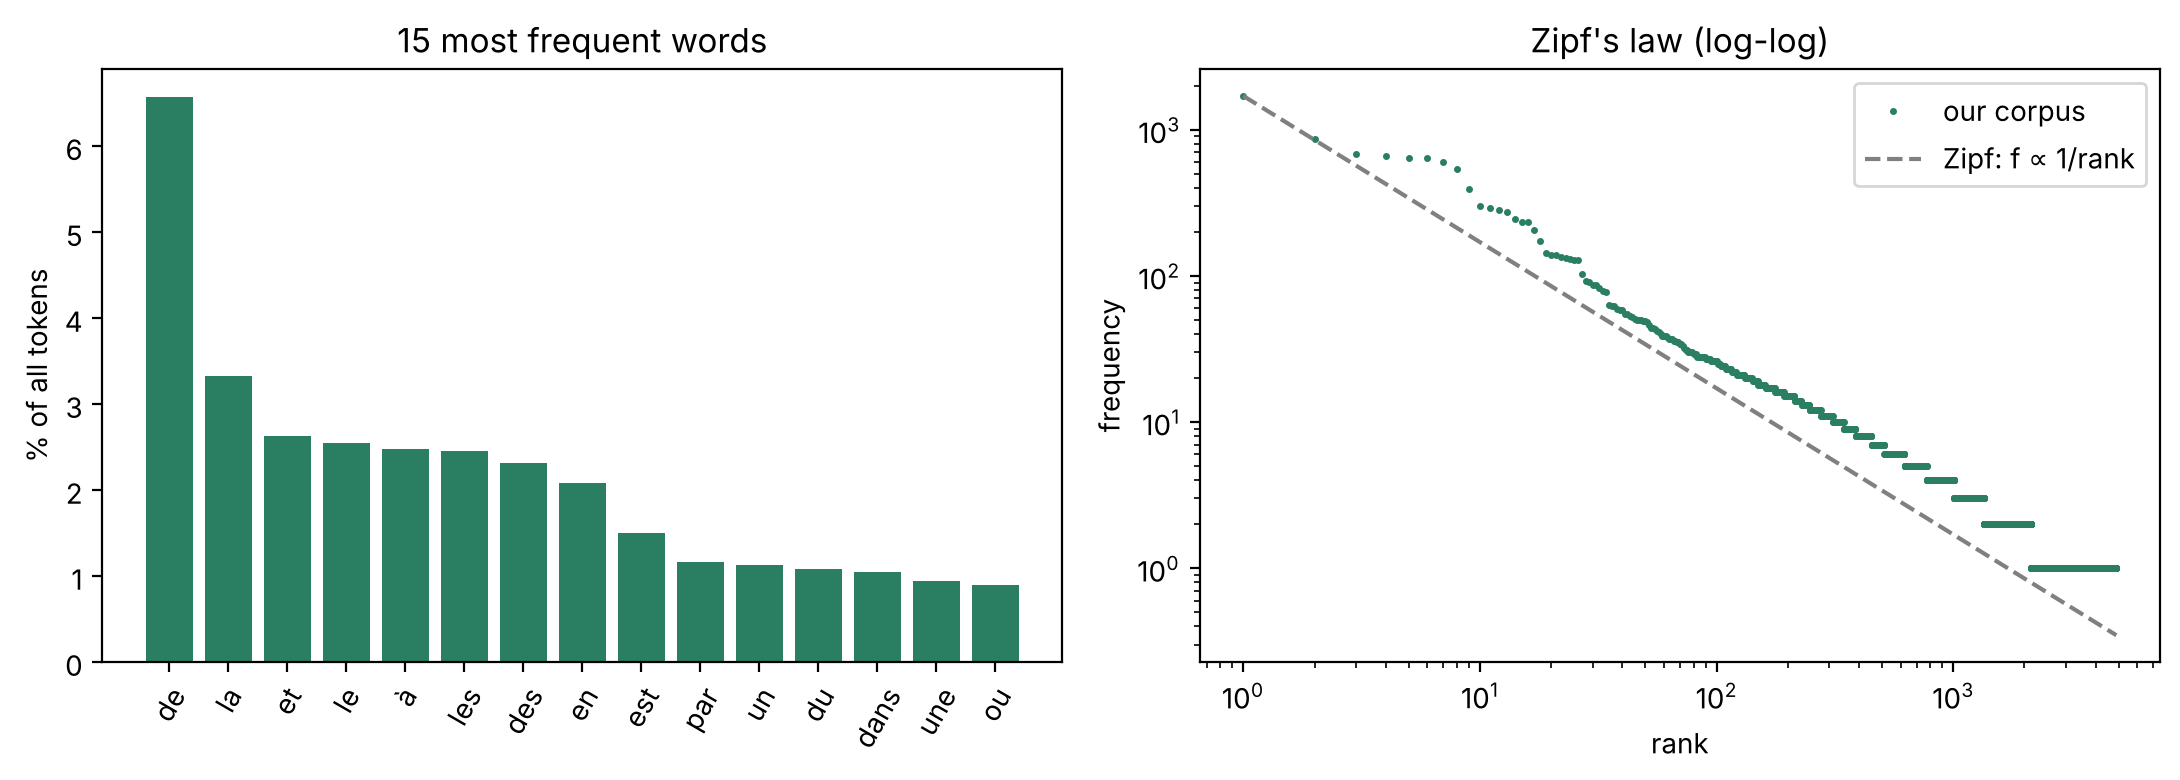

In [25]:
import numpy as np
import matplotlib.pyplot as plt

freq = Counter(w for ws_ in words for w in ws_)
ranked = freq.most_common()
total = sum(freq.values())
r = np.arange(1, len(ranked) + 1); f = np.array([c for _, c in ranked])
slope, intercept = np.polyfit(np.log(r[:1000]), np.log(f[:1000]), 1)

cum = np.cumsum(f) / total
print(f'{total} tokens, {len(freq)} types')
print('Top 10:', [(w, round(100 * c / total, 1)) for w, c in ranked[:10]], '(% of all tokens)')
print(f'The {int(np.argmax(cum >= 0.5)) + 1} most frequent words cover 50 % of the corpus')
print(f'{sum(c == 1 for c in f)} types ({100 * sum(c == 1 for c in f) / len(f):.0f} %) occur only once (hapax legomena)')
print(f'Zipf slope (top 1000 ranks): {slope:.2f}')

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].bar([w for w, _ in ranked[:15]], [100 * c / total for _, c in ranked[:15]], color='#2a7f62')
ax[0].set_ylabel('% of all tokens'); ax[0].set_title('15 most frequent words'); ax[0].tick_params(axis='x', rotation=60)
ax[1].loglog(r, f, '.', ms=3, color='#2a7f62', label='our corpus')
ax[1].loglog(r, f[0] / r, '--', color='grey', label='Zipf: f ∝ 1/rank')
ax[1].set_xlabel('rank'); ax[1].set_ylabel('frequency'); ax[1].set_title("Zipf's law (log-log)"); ax[1].legend()
plt.tight_layout(); Path('images').mkdir(exist_ok=True); plt.savefig('images/zipf.png', dpi=120); plt.show()

In [26]:
# The same without stop words: now the words tell us what the corpus is about
content_freq = Counter(w for ws_ in content for w in ws_)
print('Top 20 content lemmas:', content_freq.most_common(20))

Top 20 content lemmas: [('énergie', 189), ('carbone', 123), ('gaz', 103), ('émission', 102), ('climatique', 72), ('être', 66), ('pays', 62), ('serre', 57), ('eau', 54), ('environnement', 53), ('mondial', 52), ('production', 50), ('utiliser', 47), ('solaire', 45), ('pollution', 45), ('renouvelable', 45), ('changement', 42), ('article', 39), ('énergétique', 39), ('france', 39)]


**Zipf's law in our corpus.**
- The corpus has 25,882 tokens and 4,890 types.
- The most frequent word, ***de***, alone is **6.6 %** of all tokens. In English, *the* is about 7 % of the Brown Corpus.
- Only **89 words cover 50 %** of the corpus. The Brown Corpus needs 135, but it is 40 times larger.
- **56 %** of the types occur only once (*hapax legomena*).
- The fitted slope on the log-log plot is **−0.90**, close to the −1 of Zipf's law. The law holds for French environmental texts too.

**Implications.** The 10 most frequent words are all function words (*de, la, et, le, à, les, des, en, est, par*): they glue sentences together but carry no topic. Once stop words are removed, the frequency list shows what the corpus is about: *énergie, carbone, gaz, émission, climatique*.

Two things to fix in Week 6: *être* is still there (some forms of *être* are not flagged as stop words before lemmatization), and so is *article* (it comes from the talk pages: *l'article*).